# Glass Type Classification

This is a Glass Identification Data Set from UCI. It contains 10 attributes including id. The response is glass type(discrete 7 values). so we'll be looking in to the data do EDA on it and try some classification algorithim and see which one is the best for this work and save the trained model

In [2]:
import pandas as pd 

df = pd.read_csv("glass.csv")
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [4]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [5]:
df.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
df.drop_duplicates(inplace=True)

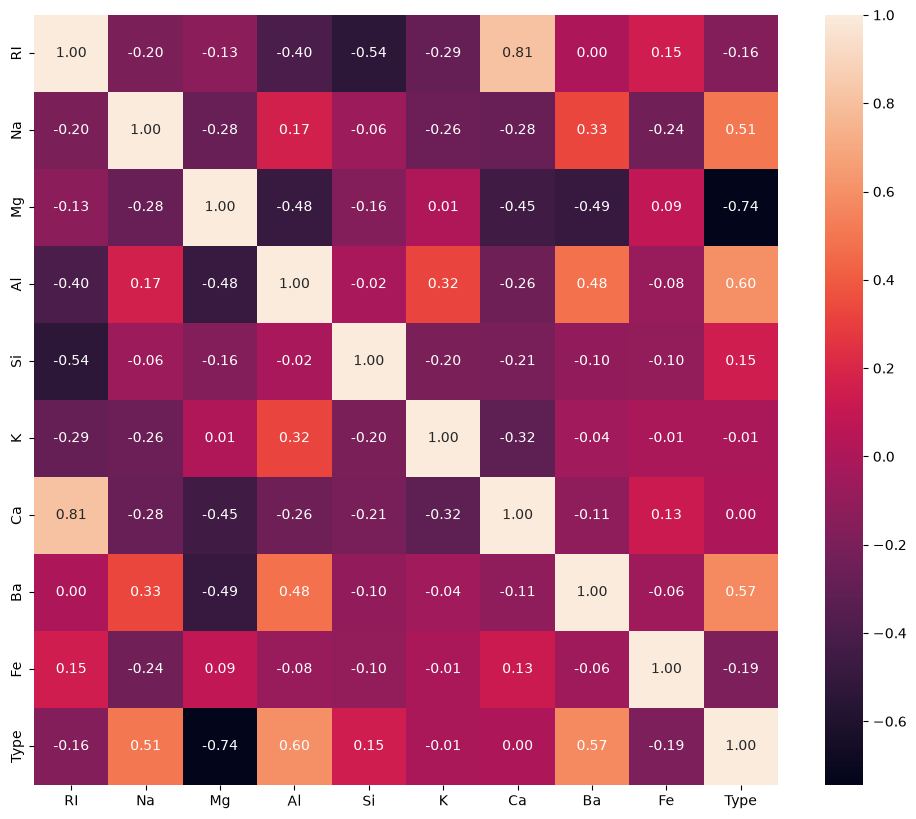

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(),annot=True, fmt=".2f")
plt.show()

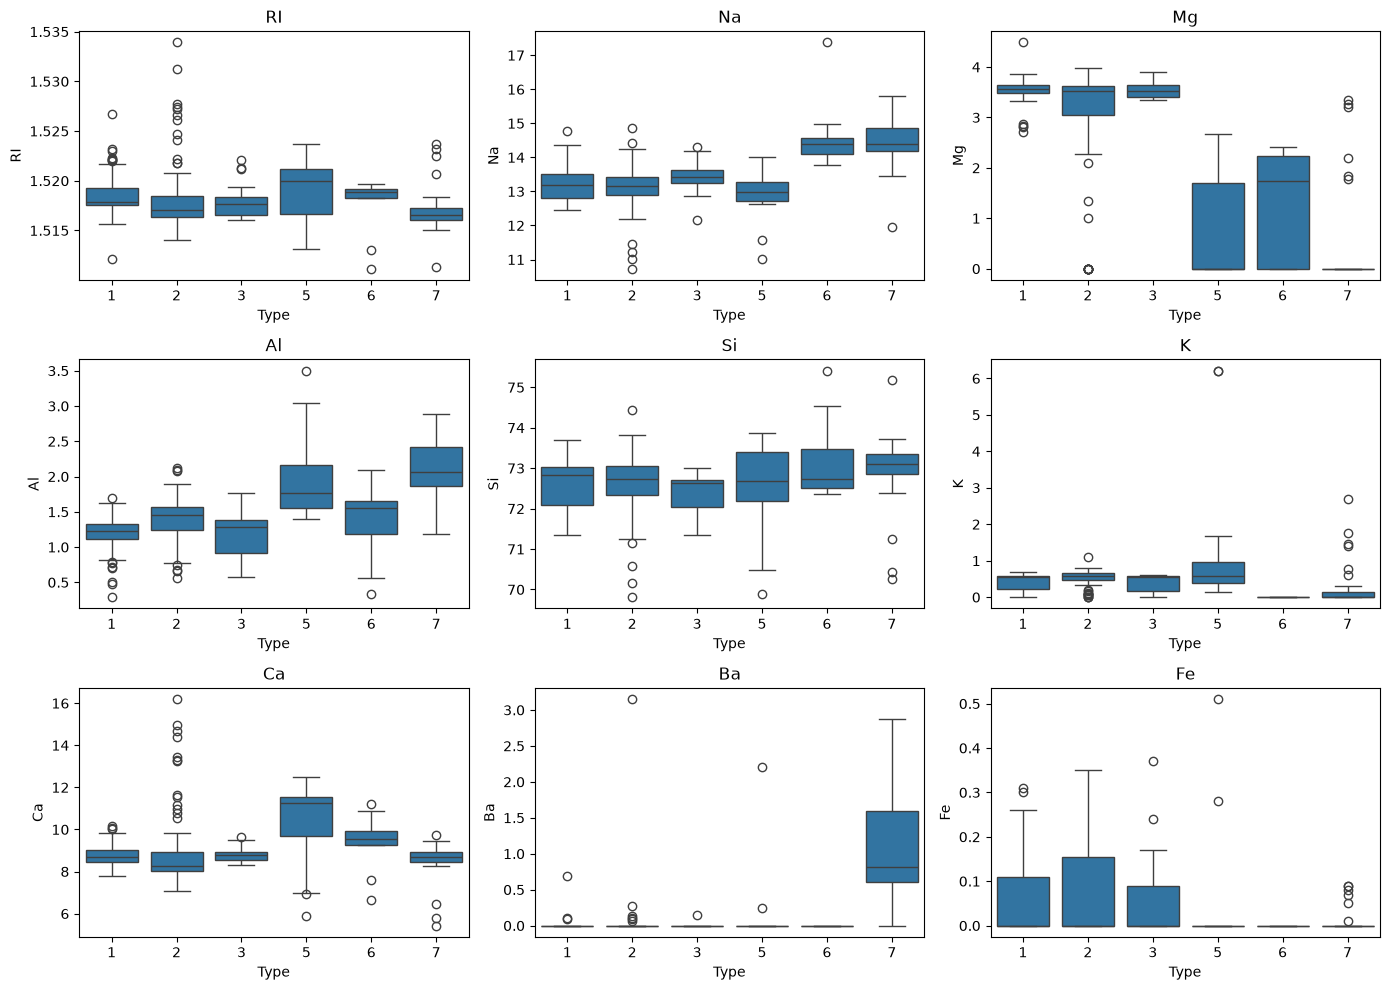

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), df.columns.drop("Type")):
    sns.boxplot(data=df, x="Type", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [10]:
x = df.drop("Type", axis=1)
y = df["Type"]


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,  classification_report
from sklearn.model_selection import train_test_split

def algo_test(x, y):
    modeller = [
        LogisticRegression(max_iter=1000),
        DecisionTreeClassifier(random_state=42),
        RandomForestClassifier(random_state=42),
        GradientBoostingClassifier(random_state=42),
        KNeighborsClassifier(),
        AdaBoostClassifier(random_state=42),
    ]
    isimler = [
        "LogisticRegression",
        "DecisionTreeClassifier",
        "RandomForestClassifier",
        "GradientBoostingClassifier",
        "KNeighborsClassifier",
        "AdaBoostClassifier",
    ]

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.20, random_state=42, stratify=y
    )

    accuracy, precision, recall, f1, mdl = [], [], [], [], []

    for model in modeller:
        model.fit(x_train, y_train)
        tahmin = model.predict(x_test)
        mdl.append(model)
        accuracy.append(accuracy_score(y_test, tahmin))
        precision.append(precision_score(y_test, tahmin, average="weighted", zero_division=0))
        recall.append(recall_score(y_test, tahmin, average="weighted", zero_division=0))
        f1.append(f1_score(y_test, tahmin, average="weighted", zero_division=0))

    metrics = pd.DataFrame(
        {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1, "Model": mdl},
        index=isimler,
    )
    metrics.sort_values("F1", ascending=False, inplace=True)
    return metrics, x_test, y_test

metrics, x_test, y_test = algo_test(x, y)
metrics.drop("Model", axis=1)

C:\Users\esref\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy,Precision,Recall,F1
RandomForestClassifier,0.860465,0.867996,0.860465,0.859663
GradientBoostingClassifier,0.790698,0.804097,0.790698,0.786577
DecisionTreeClassifier,0.697674,0.720426,0.697674,0.695043
KNeighborsClassifier,0.651163,0.653285,0.651163,0.641249
LogisticRegression,0.651163,0.625415,0.651163,0.629287
AdaBoostClassifier,0.441860,0.444544,0.441860,0.436126


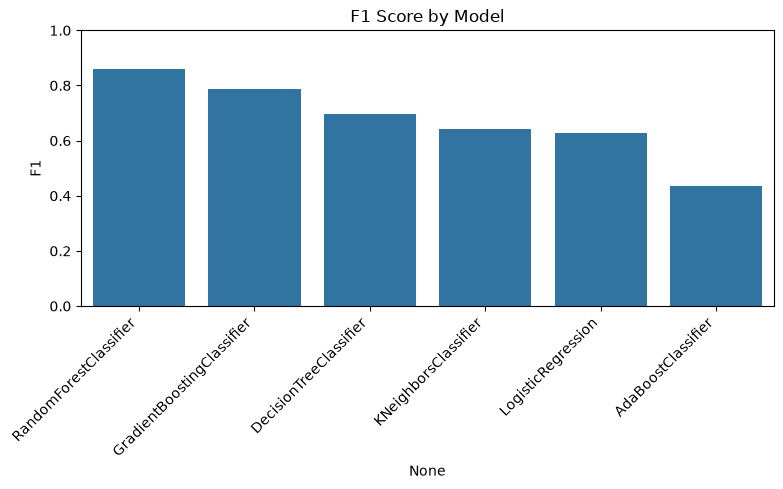

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(x=metrics.index, y=metrics["F1"])
plt.title("F1 Score by Model")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

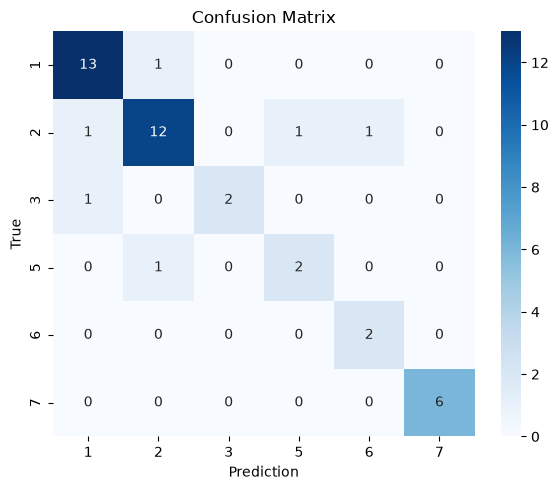

In [13]:
best = metrics.iloc[0]["Model"]
pred = best.predict(x_test)
labels = sorted(y.unique())

plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("True")
plt.tight_layout()
plt.show()

Accuracy : 0.6976744186046512
Precision: 0.7036821705426356
Recall   : 0.6976744186046512
F1       : 0.6897697909325816
              precision    recall  f1-score   support

           1       0.69      0.79      0.73        14
           2       0.67      0.53      0.59        15
           3       0.50      0.33      0.40         3
           5       0.60      1.00      0.75         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.70        43
   macro avg       0.69      0.75      0.70        43
weighted avg       0.70      0.70      0.69        43



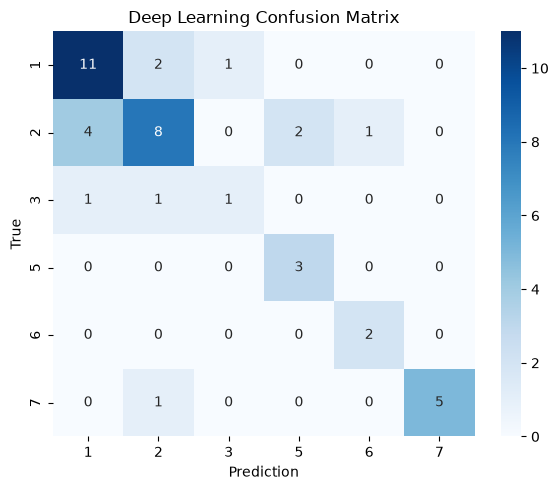

In [14]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

labels = sorted(y.unique())
y_enc = y.map({label: i for i, label in enumerate(labels)})

x_train, x_test, y_train, y_test = train_test_split(
    x.astype(float), y_enc, test_size=0.20, random_state=42, stratify=y_enc
)

x_scaler = StandardScaler()
x_tr = x_scaler.fit_transform(x_train)
x_te = x_scaler.transform(x_test)
y_tr = y_train.to_numpy()

weights = compute_class_weight("balanced", classes=np.unique(y_tr), y=y_tr)
class_weight = dict(zip(np.unique(y_tr), weights))

dl = keras.Sequential([
    keras.layers.Input(shape=(x_tr.shape[1],)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(len(labels), activation="softmax"),
])
dl.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
dl.fit(
    x_tr, y_tr,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)],
    verbose=0,
)

pred_idx = dl.predict(x_te, verbose=0).argmax(axis=1)
pred = np.array(labels)[pred_idx]
y_true = np.array(labels)[y_test.to_numpy()]

print("Accuracy :", accuracy_score(y_true, pred))
print("Precision:", precision_score(y_true, pred, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_true, pred, average="weighted", zero_division=0))
print("F1       :", f1_score(y_true, pred, average="weighted", zero_division=0))
print(classification_report(y_true, pred, zero_division=0))

plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_true, pred, labels=labels),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels,
)
plt.title("Deep Learning Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [15]:
import joblib
joblib.dump(best, "Classification3Glass_prediction.joblib")

['Classification3Glass_prediction.joblib']

# Conclusion

I loaded the glass data, checked for missing values and dropped the duplicate rows. The features are all numeric, so I looked at the correlation heatmap and then compared every column with Type using a grouped mean table and boxplots. Types 1 and 2 have most of the samples, and Mg, Al, Ba and RI separate the glass types more clearly than the other columns. The best test result was Random Forest Classifier with a 85 of F1. The confusion matrix showed that the window-glass types are easy to mix up, and the smaller classes are harder because there are fewer rows.